# Credit Risk Analytics Platform

## 03 - Exploratory Data Analysis

### Business Objective

The objective of this notebook is to explore the
credit card portfolio and identify factors associated
with customer default.

### Key Business Questions

1. What is the overall default rate?
2. How does credit risk vary across customer segments?
3. Is credit limit associated with default risk?
4. How does repayment behavior relate to default?
5. Which variables may be useful for predictive modeling?

### Methodology

- Descriptive statistics
- Univariate analysis
- Bivariate analysis
- Portfolio segmentation
- Correlation analysis
- Business interpretation

In [28]:
# Technical setup: import the libraries used for exploratory analysis, data summarisation and visualisation.

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

RANDOM_STATE = 42



In [29]:
# Technical setup: define repository paths so all generated outputs are saved in the correct project folders.

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"
OUTPUT_PATH = PROJECT_ROOT / "data" / "outputs"
FIGURES_PATH = PROJECT_ROOT / "reports" / "figures"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

DATA_FILE = RAW_PATH / "credit_card_default.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
print("Number of clients:", len(df))

display(df.head())


Dataset shape: (30000, 24)
Number of clients: 30000


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [30]:
# Step 1: validate the core credit-risk columns required for portfolio analysis.

required_columns = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "DEFAULT"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns validation: OK")


Required columns validation: OK


In [31]:
# Business summary: compute the baseline portfolio KPIs used to understand customer risk exposure.

portfolio_overview = pd.DataFrame({
    "Metric": [
        "Number of clients",
        "Total credit limit",
        "Average credit limit",
        "Median credit limit",
        "Average age",
        "Minimum age",
        "Maximum age"
    ],
    "Value": [
        len(df),
        df["LIMIT_BAL"].sum(),
        df["LIMIT_BAL"].mean(),
        df["LIMIT_BAL"].median(),
        df["AGE"].mean(),
        df["AGE"].min(),
        df["AGE"].max()
    ]
})

display(portfolio_overview)


,Metric,Value
0,Number of clients,"30,000.00"
1,Total credit limit,"5,024,529,680.00"
2,Average credit limit,"167,484.32"
3,Median credit limit,"140,000.00"
4,Average age,35.49
5,Minimum age,21.00
6,Maximum age,79.00


## 1. Credit limit and default behavior


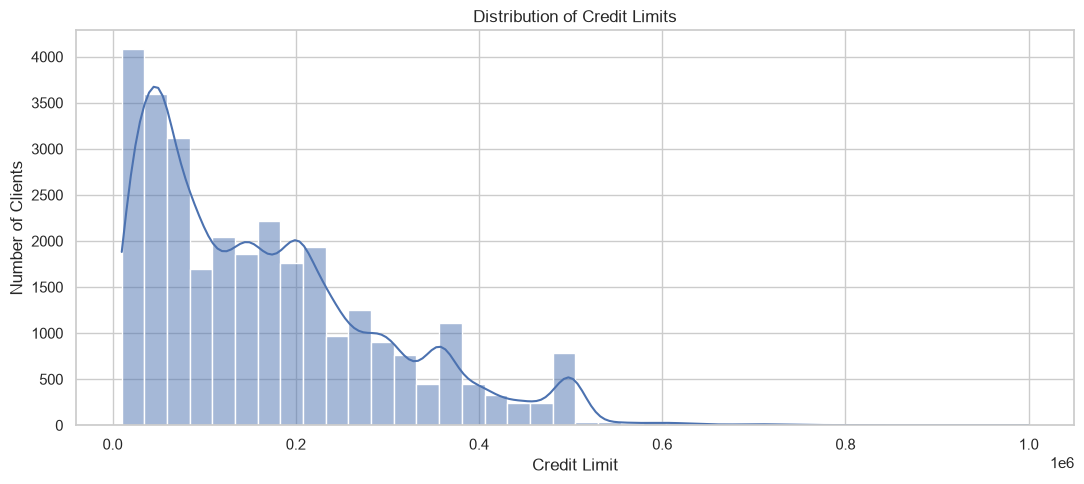

In [32]:
# Business insight: inspect the distribution of credit limits to understand portfolio exposure and concentration.

plt.figure(figsize=(11, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Clients")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "01_credit_limit_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [33]:
# Business summary: quantify the default rate and class balance in the portfolio.

target_distribution = (
    df["DEFAULT"]
    .value_counts()
    .sort_index()
)

target_rate = (
    df["DEFAULT"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

default_summary = pd.DataFrame({
    "Number of clients": target_distribution,
    "Percentage": target_rate
})

display(default_summary)


,Number of clients,Percentage
DEFAULT,,
0,23364,77.88
1,6636,22.12


In [34]:
# Executive KPI: calculate the overall default rate to establish the baseline risk level.

default_rate = df["DEFAULT"].mean()

print(f"Portfolio default rate: {default_rate:.2%}")


Portfolio default rate: 22.12%


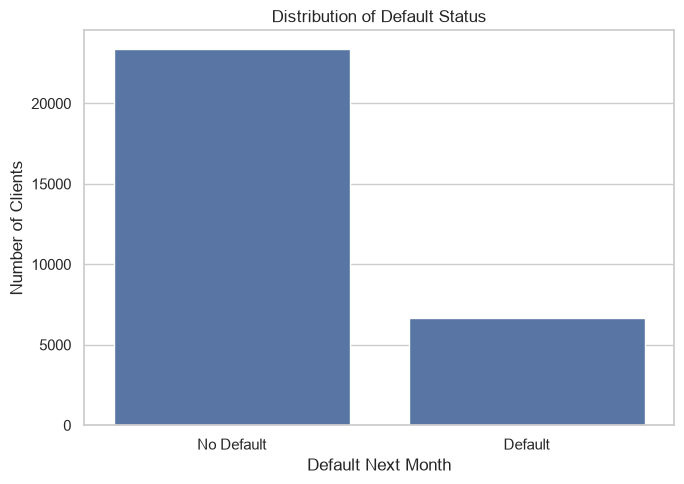

In [35]:
# Visualization: confirm the target distribution and the relative share of defaulted accounts.

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="DEFAULT"
)

plt.title("Distribution of Default Status")
plt.xlabel("Default Next Month")
plt.ylabel("Number of Clients")

plt.xticks(
    ticks=[0, 1],
    labels=["No Default", "Default"]
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "02_default_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [36]:
# Feature engineering: group credit limits into practical risk bands for segment-level comparison.

df["LIMIT_GROUP"] = pd.cut(
    df["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 300000, 500000, np.inf],
    labels=[
        "0-50k",
        "50-100k",
        "100-200k",
        "200-300k",
        "300-500k",
        "500k+"
    ],
    include_lowest=True
)


In [37]:
# Business analysis: compare default rates across credit-limit buckets to detect risk concentration.

limit_analysis = (
    df.groupby("LIMIT_GROUP", observed=False)
    .agg(
        CLIENTS=("DEFAULT", "size"),
        DEFAULTS=("DEFAULT", "sum"),
        DEFAULT_RATE=("DEFAULT", "mean"),
        AVG_LIMIT=("LIMIT_BAL", "mean")
    )
    .reset_index()
)

limit_analysis["DEFAULT_RATE"] *= 100

display(limit_analysis)


,LIMIT_GROUP,CLIENTS,DEFAULTS,DEFAULT_RATE,AVG_LIMIT
0,0-50k,7676,2440,31.79,"35,204.79"
1,50-100k,4822,1244,25.80,"80,759.02"
2,100-200k,7880,1535,19.48,"158,327.41"
3,200-300k,5059,812,16.05,"250,430.92"
4,300-500k,4357,582,13.36,"396,386.89"
5,500k+,206,23,11.17,"598,398.06"


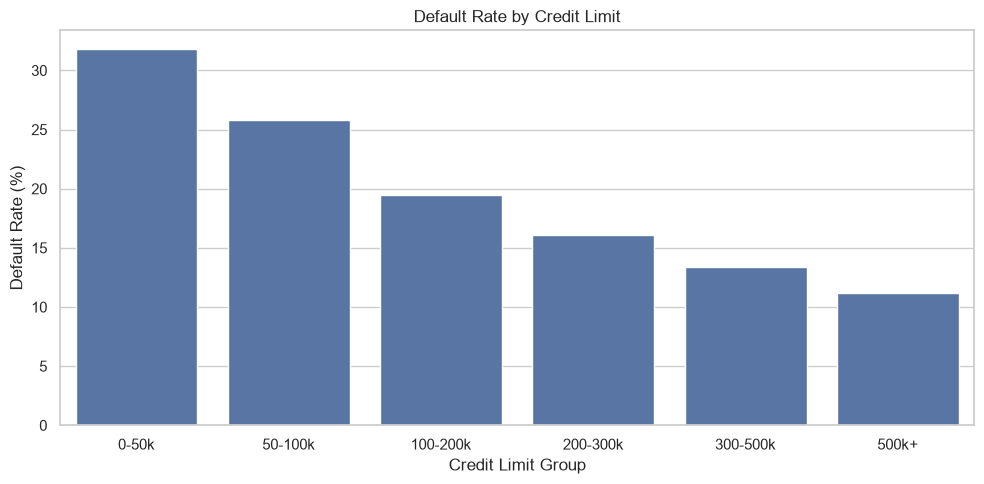

In [38]:
# Visualization: show how default risk changes as loan size increases or decreases.

plt.figure(figsize=(10, 5))

sns.barplot(
    data=limit_analysis,
    x="LIMIT_GROUP",
    y="DEFAULT_RATE"
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "03_default_by_credit_limit.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 2. Age segmentation and default risk


In [39]:
# Feature engineering: bucket customer age into lifecycle groups to test age-related default risk.

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ],
    include_lowest=True
)

age_analysis = (
    df.groupby("AGE_GROUP", observed=False)
    .agg(
        CLIENTS=("DEFAULT", "size"),
        DEFAULTS=("DEFAULT", "sum"),
        DEFAULT_RATE=("DEFAULT", "mean")
    )
    .reset_index()
)

age_analysis["DEFAULT_RATE"] *= 100

display(age_analysis)


,AGE_GROUP,CLIENTS,DEFAULTS,DEFAULT_RATE
0,18-25,3871,1032,26.66
1,26-35,12938,2565,19.83
2,36-45,8522,1861,21.84
3,46-55,3825,954,24.94
4,56-65,758,201,26.52
5,65+,86,23,26.74


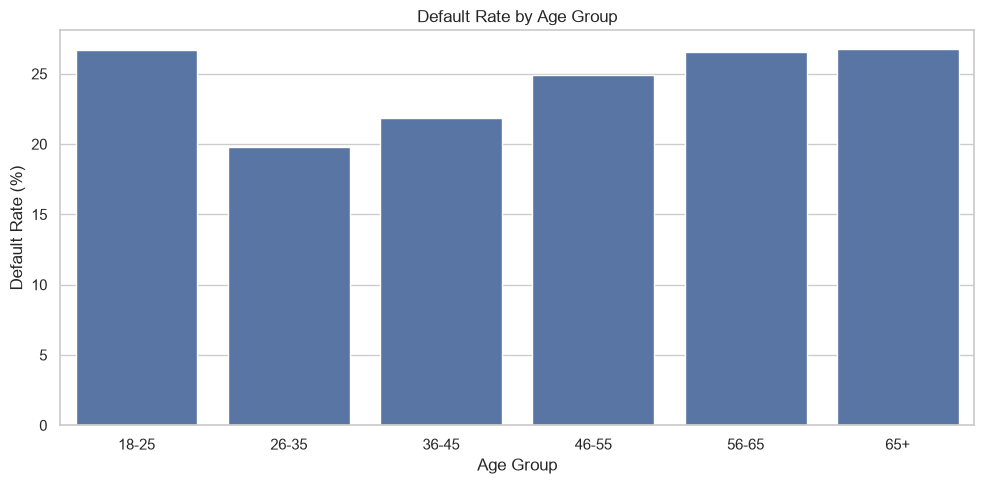

In [40]:
# Business insight: inspect whether older or younger customers show materially different default rates.

plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_analysis,
    x="AGE_GROUP",
    y="DEFAULT_RATE"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "04_default_by_age.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 3. Demographic profile and default rate



Default rate by SEX


,SEX,CLIENTS,DEFAULTS,DEFAULT_RATE
0,1,11888,2873,24.17
1,2,18112,3763,20.78


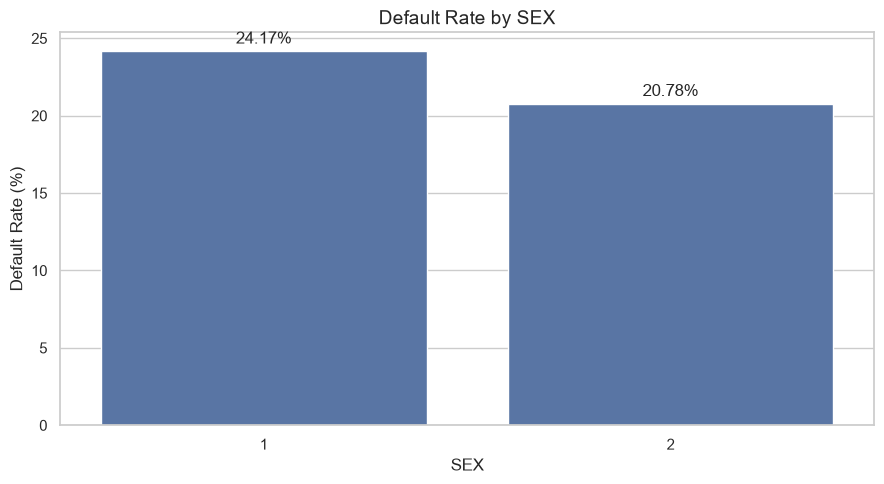

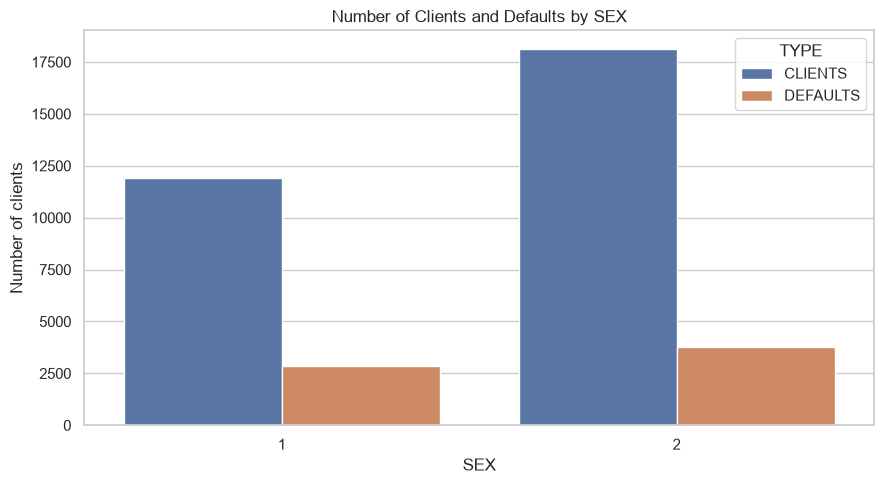


Default rate by EDUCATION


,EDUCATION,CLIENTS,DEFAULTS,DEFAULT_RATE
0,0,14,0,0.00
1,1,10585,2036,19.23
2,2,14030,3330,23.73
3,3,4917,1237,25.16
4,4,123,7,5.69
5,5,280,18,6.43
6,6,51,8,15.69


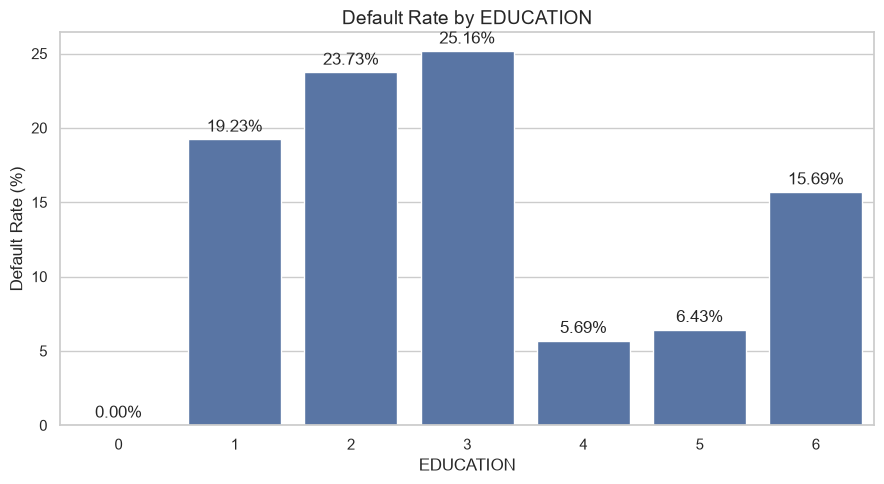

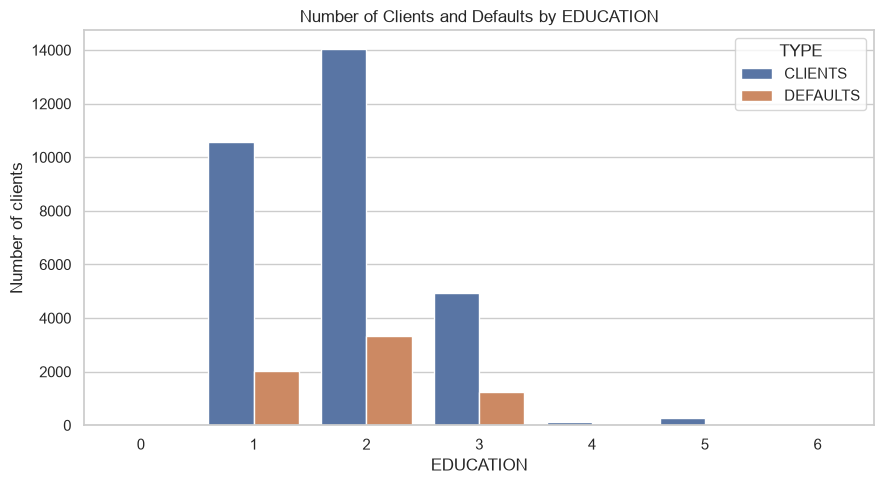


Default rate by MARRIAGE


,MARRIAGE,CLIENTS,DEFAULTS,DEFAULT_RATE
0,0,54,5,9.26
1,1,13659,3206,23.47
2,2,15964,3341,20.93
3,3,323,84,26.01


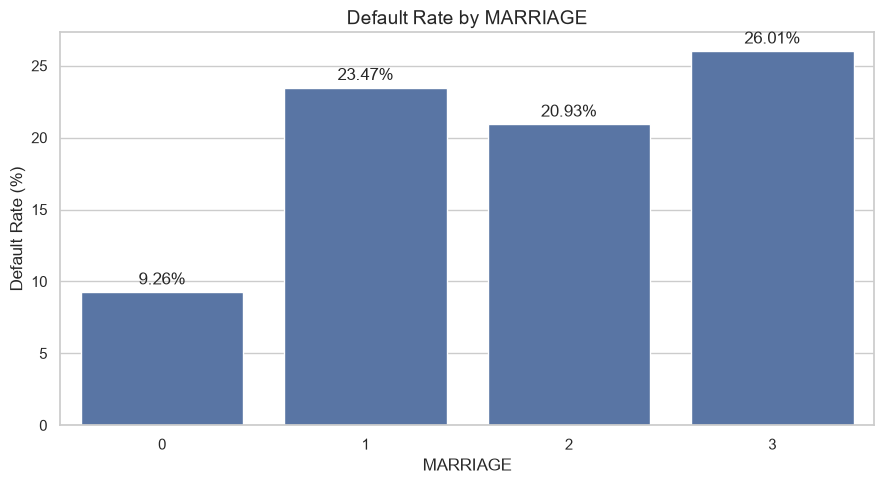

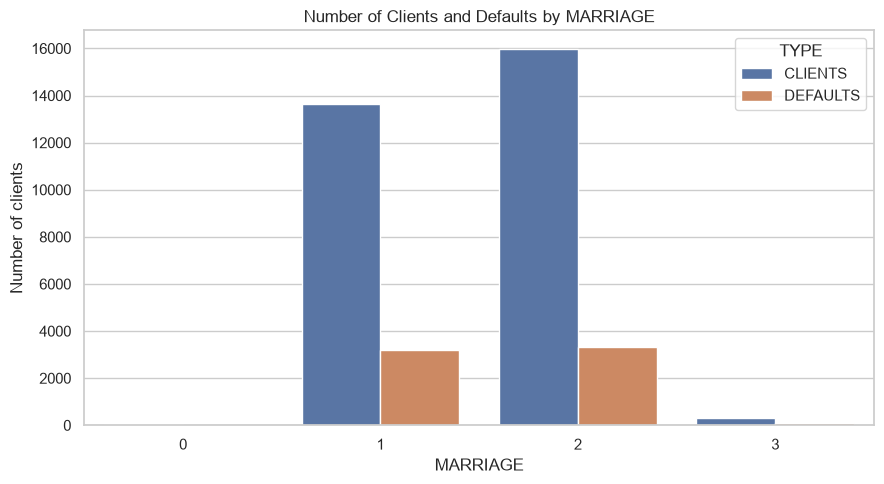

In [41]:
# Business analysis: compare default rates across customer demographic segments.

categorical_columns = [
    col for col in ["SEX", "EDUCATION", "MARRIAGE"]
    if col in df.columns
]

for col in categorical_columns:

    analysis = (
        df.groupby(col, dropna=False)
        .agg(
            CLIENTS=("DEFAULT", "size"),
            DEFAULTS=("DEFAULT", "sum"),
            DEFAULT_RATE=("DEFAULT", "mean")
        )
        .reset_index()
    )

    analysis["DEFAULT_RATE"] *= 100

    print(f"\nDefault rate by {col}")
    display(analysis.round(2))

    # Wykres 1 – Default Rate
    plt.figure(figsize=(9, 5))

    ax = sns.barplot(
        data=analysis,
        x=col,
        y="DEFAULT_RATE"
    )

    ax.set_title(f"Default Rate by {col}", fontsize=14)
    ax.set_xlabel(col)
    ax.set_ylabel("Default Rate (%)")

    # Etykiety wartości
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.tight_layout()
    plt.show()

    # Wykres 2 – liczba klientów i defaultów
    plt.figure(figsize=(9, 5))

    analysis_plot = analysis.melt(
        id_vars=col,
        value_vars=["CLIENTS", "DEFAULTS"],
        var_name="TYPE",
        value_name="COUNT"
    )

    sns.barplot(
        data=analysis_plot,
        x=col,
        y="COUNT",
        hue="TYPE"
    )

    plt.title(f"Number of Clients and Defaults by {col}")
    plt.xlabel(col)
    plt.ylabel("Number of clients")
    plt.tight_layout()
    plt.show()


## 4. Repayment behavior and delinquency


In [42]:
# Business analysis: review repayment behavior by status code to understand the relationship with default risk.

payment_columns = [
    col for col in [
        "PAY_0",
        "PAY_2",
        "PAY_3",
        "PAY_4",
        "PAY_5",
        "PAY_6"
    ]
    if col in df.columns
]

for col in payment_columns:
    print(f"\nDistribution: {col}")
    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )



Distribution: PAY_0


PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


Distribution: PAY_2


PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64


Distribution: PAY_3


PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

... (2 outputs left out)


Distribution: PAY_5


PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64


Distribution: PAY_6


PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int64

In [43]:
# Feature engineering: create a delinquency flag that summarizes any late payment in the recent repayment history.

df["ANY_PAST_DUE"] = (
    df[payment_columns]
    .gt(0)
    .any(axis=1)
    .astype(int)
)

past_due_analysis = (
    df.groupby("ANY_PAST_DUE")
    .agg(
        CLIENTS=("DEFAULT", "size"),
        DEFAULTS=("DEFAULT", "sum"),
        DEFAULT_RATE=("DEFAULT", "mean")
    )
    .reset_index()
)

past_due_analysis["DEFAULT_RATE"] *= 100

past_due_analysis["ANY_PAST_DUE"] = (
    past_due_analysis["ANY_PAST_DUE"]
    .map({
        0: "No recorded delay",
        1: "At least one delay"
    })
)

display(past_due_analysis)


,ANY_PAST_DUE,CLIENTS,DEFAULTS,DEFAULT_RATE
0,No recorded delay,19931,2334,11.71
1,At least one delay,10069,4302,42.73


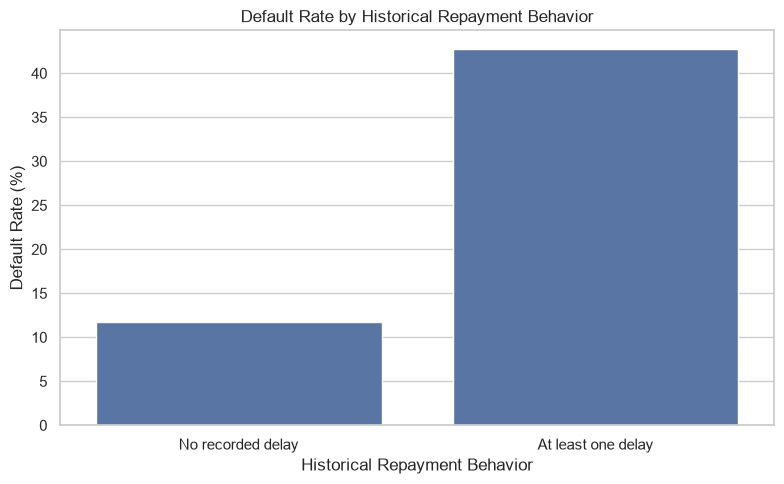

In [44]:
# Visualization: compare default risk between customers with and without recent late-payment history.

plt.figure(figsize=(8, 5))

sns.barplot(
    data=past_due_analysis,
    x="ANY_PAST_DUE",
    y="DEFAULT_RATE"
)

plt.title("Default Rate by Historical Repayment Behavior")
plt.xlabel("Historical Repayment Behavior")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "05_default_by_past_due.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [45]:
# Technical summary: compute the default probability by each repayment-status code to estimate behavioral risk.

pay0_analysis = (
    df.groupby("PAY_0", dropna=False)
    .agg(
        CLIENTS=("DEFAULT", "size"),
        DEFAULTS=("DEFAULT", "sum"),
        DEFAULT_RATE=("DEFAULT", "mean")
    )
    .reset_index()
)

pay0_analysis["DEFAULT_RATE"] *= 100

display(pay0_analysis)


,PAY_0,CLIENTS,DEFAULTS,DEFAULT_RATE
0,-2,2759,365,13.23
1,-1,5686,954,16.78
2,0,14737,1888,12.81
3,1,3688,1252,33.95
4,2,2667,1844,69.14
5,3,322,244,75.78
6,4,76,52,68.42
7,5,26,13,50.00
8,6,11,6,54.55
9,7,9,7,77.78


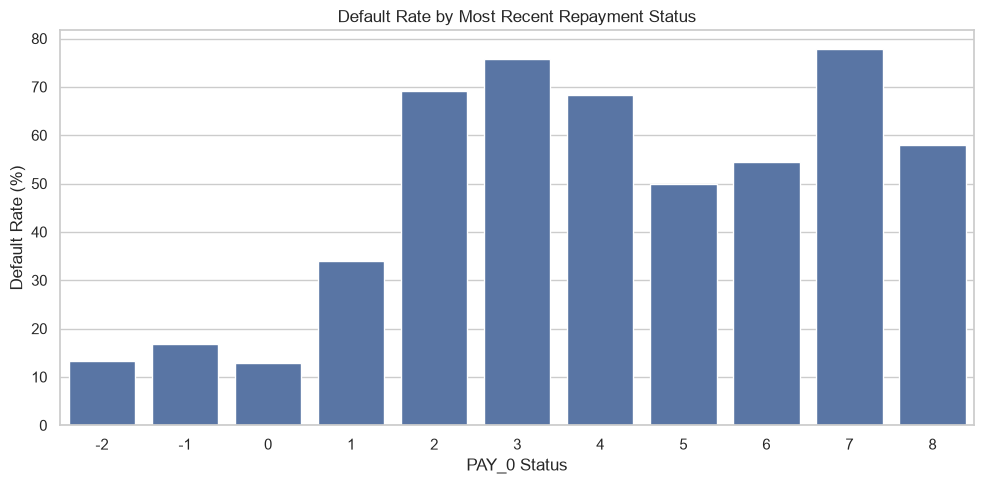

In [46]:
# Visualization: map repayment-status categories to default intensity for operational interpretation.

plt.figure(figsize=(10, 5))

sns.barplot(
    data=pay0_analysis,
    x="PAY_0",
    y="DEFAULT_RATE"
)

plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("PAY_0 Status")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "06_default_by_pay0.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 5. Correlation analysis


In [47]:
# Technical review: assess correlations among the main financial and behavioral variables.

correlation_columns = [
    col for col in [
        "LIMIT_BAL",
        "AGE",
        "BILL_AMT1",
        "BILL_AMT2",
        "BILL_AMT3",
        "PAY_AMT1",
        "PAY_AMT2",
        "PAY_AMT3",
        "DEFAULT"
    ]
    if col in df.columns
]

correlation_matrix = df[
    correlation_columns
].corr(method="spearman")

display(correlation_matrix)


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,PAY_AMT1,PAY_AMT2,PAY_AMT3,DEFAULT
LIMIT_BAL,1.00,0.19,0.05,0.05,0.06,0.27,0.28,0.28,-0.17
AGE,0.19,1.00,0.00,0.00,0.00,0.03,0.04,0.03,0.01
BILL_AMT1,0.05,0.00,1.00,0.91,0.86,0.50,0.47,0.44,-0.03
BILL_AMT2,0.05,0.00,0.91,1.00,0.91,0.64,0.50,0.47,-0.02
BILL_AMT3,0.06,0.00,0.86,0.91,1.00,0.55,0.64,0.49,-0.01
PAY_AMT1,0.27,0.03,0.50,0.64,0.55,1.00,0.51,0.52,-0.16
PAY_AMT2,0.28,0.04,0.47,0.50,0.64,0.51,1.00,0.52,-0.15
PAY_AMT3,0.28,0.03,0.44,0.47,0.49,0.52,0.52,1.00,-0.14
DEFAULT,-0.17,0.01,-0.03,-0.02,-0.01,-0.16,-0.15,-0.14,1.00


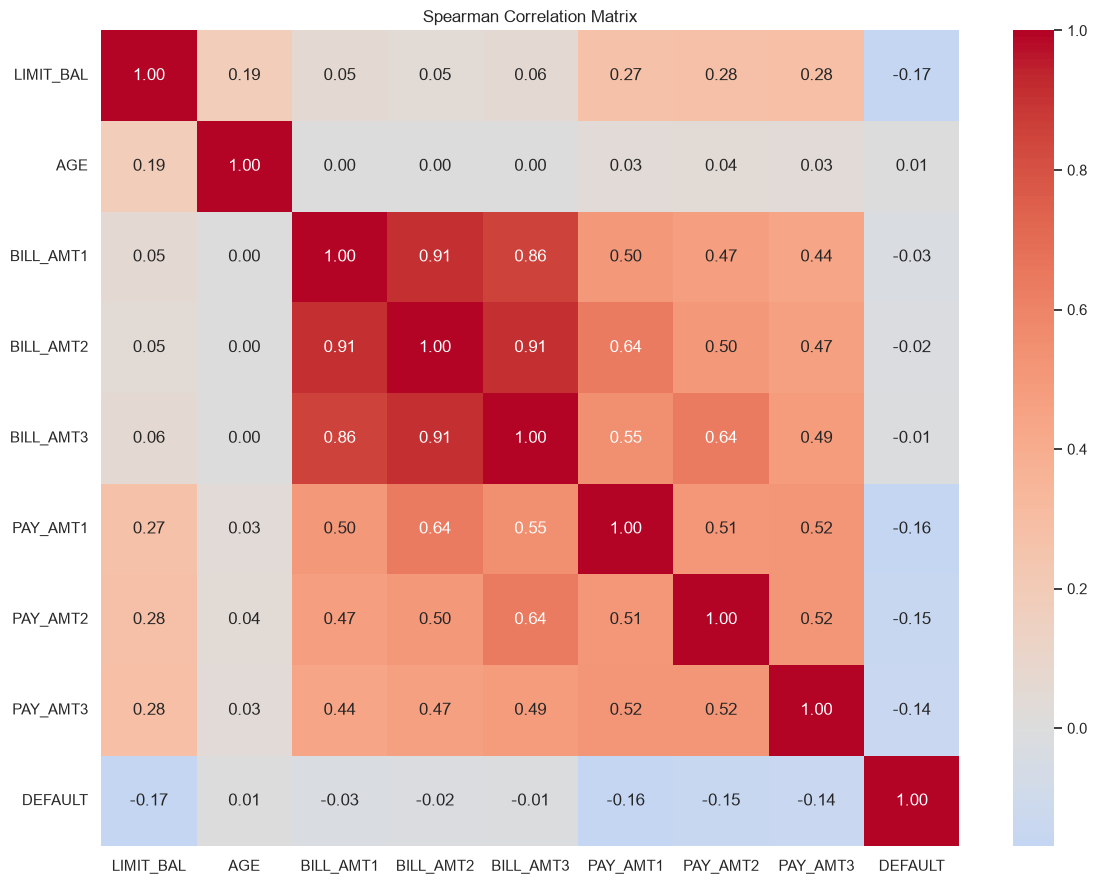

In [48]:
# Visualization: inspect the relationship structure to identify redundant or signal-rich predictors.

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "07_correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 6. Key findings and recommendations


In [49]:
# Executive summary: consolidate the main observations that matter for business and model decisions.

eda_summary = pd.DataFrame({
    "Metric": [
        "Number of clients",
        "Overall default rate",
        "Average credit limit",
        "Median credit limit",
        "Average age",
        "Clients with past due",
        "Default rate - clients with past due",
        "Default rate - clients without past due"
    ],
    "Value": [
        len(df),
        df["DEFAULT"].mean(),
        df["LIMIT_BAL"].mean(),
        df["LIMIT_BAL"].median(),
        df["AGE"].mean(),
        df["ANY_PAST_DUE"].sum(),
        df.loc[df["ANY_PAST_DUE"] == 1, "DEFAULT"].mean(),
        df.loc[df["ANY_PAST_DUE"] == 0, "DEFAULT"].mean()
    ]
})

display(eda_summary)


,Metric,Value
0,Number of clients,"30,000.00"
1,Overall default rate,0.22
2,Average credit limit,"167,484.32"
3,Median credit limit,"140,000.00"
4,Average age,35.49
5,Clients with past due,"10,069.00"
6,Default rate - clients with past due,0.43
7,Default rate - clients without past due,0.12


In [50]:
# Export the final analytical summary so the outputs are reusable in reporting and model preparation.

eda_summary.to_csv(
    OUTPUT_PATH / "eda_summary.csv",
    index=False
)

limit_analysis.to_csv(
    OUTPUT_PATH / "default_by_credit_limit.csv",
    index=False
)

age_analysis.to_csv(
    OUTPUT_PATH / "default_by_age.csv",
    index=False
)

past_due_analysis.to_csv(
    OUTPUT_PATH / "default_by_past_due.csv",
    index=False
)

print("EDA outputs saved successfully.")


EDA outputs saved successfully.
